In [1]:
%load_ext autoreload
%autoreload 2

import glob

import cv2
import matplotlib.pyplot as plt
import numpy as np

from tflite_inference import TFLiteInferer

2025-04-02 19:27:40.577013: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-04-02 19:27:40.598622: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-04-02 19:27:40.607943: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-04-02 19:27:40.622507: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-04-02 19:27:41.764235: W tensorflow/compiler/tf2

TensorFlow version:  2.17.0


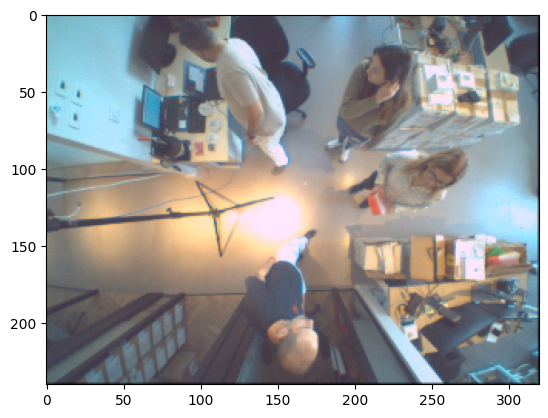

In [6]:
# tst_img_path = "../../rtos_sensor/projects/alif_ml-embedded-evaluation-kit_pg/resources/pg_object_detection/samples/img_320.bmp"
tst_img_path = "img_320.bmp"

img = cv2.cvtColor(cv2.imread(tst_img_path), cv2.COLOR_BGR2RGB)

ORIGINAL_H, ORIGIAL_W, _ = img.shape
W = H = 320
RATIO = W / ORIGIAL_W

plt.imshow(img)

In [7]:
def draw(img, detections):
    tmp = img.copy()
    for box in detections:
        cv2.rectangle(tmp, (box[:2] / RATIO).astype(int), ((box[:2].astype(int) + box[2:4]) / RATIO).astype(int) , (255, 0, 0), 1)

    for p in detections:
        cv2.circle(tmp, (p[-2:] // RATIO).astype(int), 2, (255, 0, 0), 3)

    plt.figure(figsize=(8, 8))
    plt.imshow(tmp)

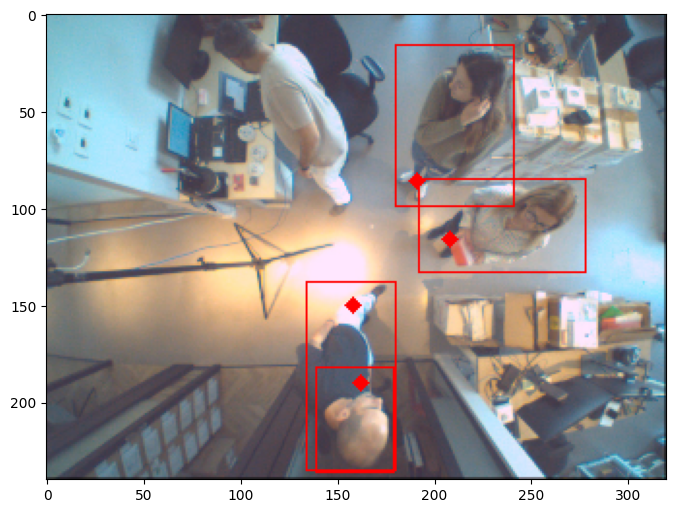

In [9]:
# baseline
alif_output = """Box: [192.01 85.60 86.31 48.80]. Position: [208.69 116.73]. Confidence: 0.77
Box: [134.75 138.14 46.02 97.38]. Position: [158.51 150.43]. Confidence: 0.77
Box: [180.03 16.42 61.53 83.72]. Position: [191.31 86.80]. Confidence: 0.71
Box: [139.96 182.95 40.87 54.08]. Position: [162.76 190.73]. Confidence: 0.64"""

detections = []
for line in alif_output.split("\n"):
    line = line.replace("[", "").replace("].", "").split(" ")
    tmp_det = [
        line[1],
        line[2],
        line[3],
        line[4],
        line[9],
        "0",
        line[6],
        line[7],
    ]
    detections.append([float(i) for i in tmp_det])

draw(img, np.array(detections))

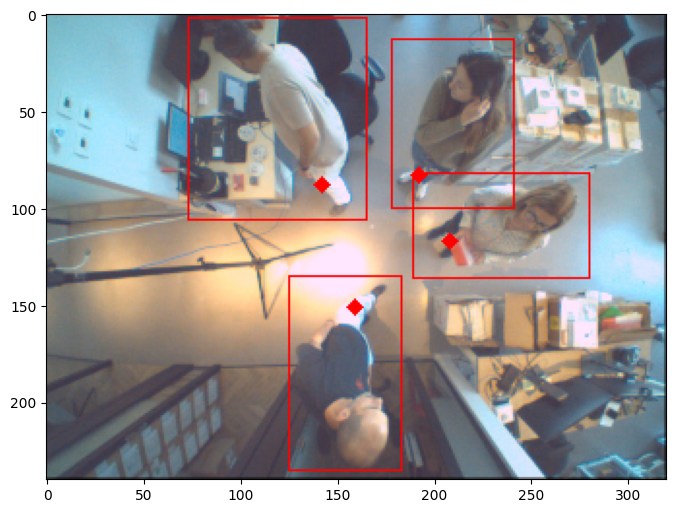

In [10]:
# input adapter
alif_output = """Box: [178.17 13.75 63.74 87.24]. Position: [192.00 83.93]. Confidence: 0.82
Box: [189.78 82.13 91.58 54.12]. Position: [208.80 117.42]. Confidence: 0.82
Box: [73.53 2.13 92.19 104.73]. Position: [142.51 88.77]. Confidence: 0.77
Box: [125.32 135.98 58.80 100.67]. Position: [159.89 151.82]. Confidence: 0.77"""

detections = []
for line in alif_output.split("\n"):
    line = line.replace("[", "").replace("].", "").split(" ")
    tmp_det = [
        line[1],
        line[2],
        line[3],
        line[4],
        line[9],
        "0",
        line[6],
        line[7],
    ]
    detections.append([float(i) for i in tmp_det])

draw(img, np.array(detections))